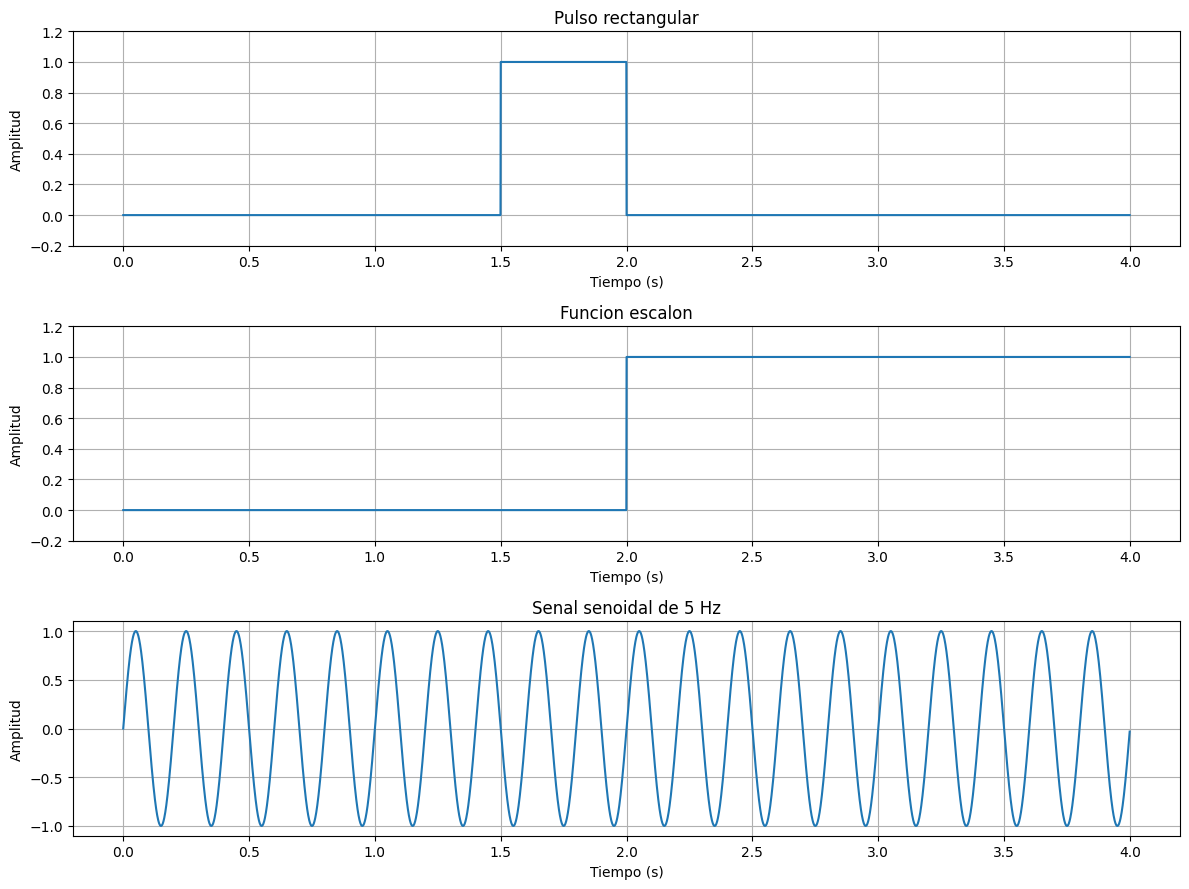

In [4]:

# ============================================================
# PROYECTO: ANALISIS DE SEÑALES CON LA TRANSFORMADA DE FOURIER
# ============================================================

# Importamos las bibliotecas necesarias.
import numpy as np
import matplotlib.pyplot as plt

# ------------------------------------------------------------
# 1. DEFINICION DE LOS PARAMETROS
# ------------------------------------------------------------

Fs = 1000                 # Frecuencia de muestreo (muestras/segundo)
T = 4                     # Duracion de la senal en segundos
dt = 1 / Fs               # Tiempo entre muestras
t = np.arange(0, T, dt)   # Vector de tiempo

# ------------------------------------------------------------
# 2. CREACION DE LAS SENALES
# ------------------------------------------------------------

# Pulso rectangular: vale 1 entre 1.5 y 2 segundos.
pulso = ((t >= 1.5) & (t < 2)).astype(float)

# Funcion escalon: cambia de 0 a 1 en el segundo 2.
escalon = (t >= 2).astype(float)

# Senal senoidal: amplitud 1 y frecuencia de 5 Hz.
f0 = 5
senoidal = np.sin(2 * np.pi * f0 * t)

# ------------------------------------------------------------
# 3. GRAFICAR LAS SENALES EN EL DOMINIO DEL TIEMPO
# ------------------------------------------------------------

plt.figure(figsize=(12, 9))

# Primera grafica: pulso rectangular.
plt.subplot(3, 1, 1)
plt.plot(t, pulso)
plt.title("Pulso rectangular")
plt.xlabel("Tiempo (s)")
plt.ylabel("Amplitud")
plt.grid(True)
plt.ylim(-0.2, 1.2)

# Segunda grafica: funcion escalon.
plt.subplot(3, 1, 2)
plt.plot(t, escalon)
plt.title("Funcion escalon")
plt.xlabel("Tiempo (s)")
plt.ylabel("Amplitud")
plt.grid(True)
plt.ylim(-0.2, 1.2)

# Tercera grafica: senal senoidal.
plt.subplot(3, 1, 3)
plt.plot(t, senoidal)
plt.title("Senal senoidal de 5 Hz")
plt.xlabel("Tiempo (s)")
plt.ylabel("Amplitud")
plt.grid(True)

plt.tight_layout()
plt.show()

# ------------------------------------------------------------
# FIN DE LA PRIMERA ETAPA
# ------------------------------------------------------------


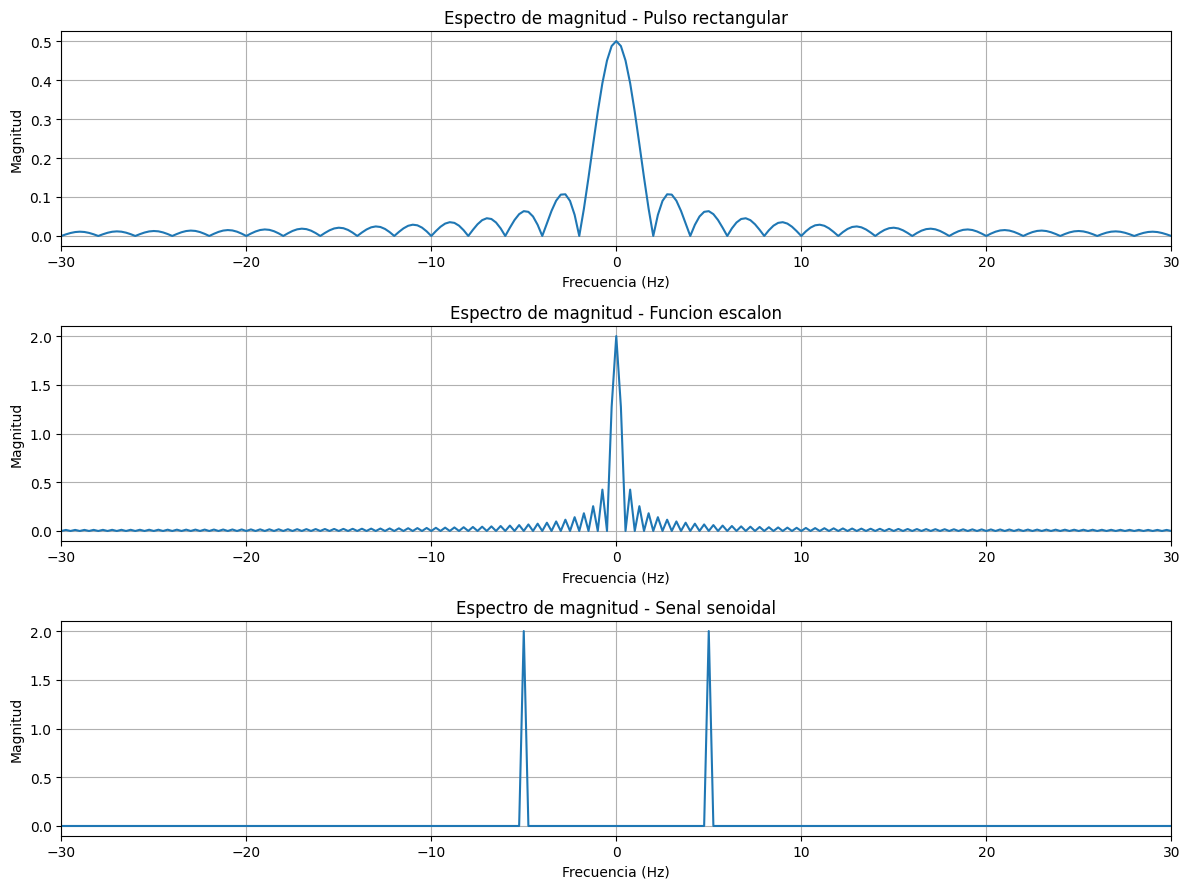

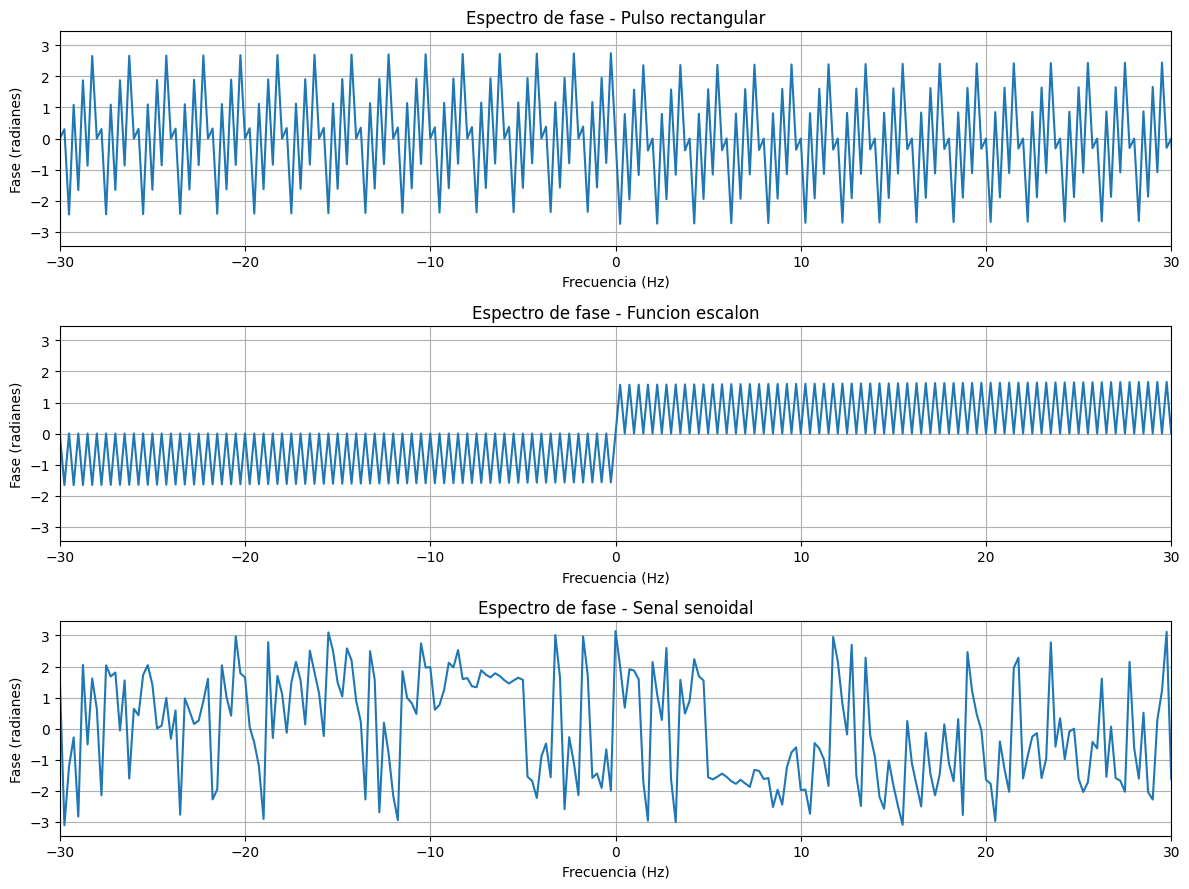

In [5]:

# ============================================================
# TRANSFORMADA DE FOURIER
# ============================================================

# Numero de muestras de cada senal.
N = len(t)

# ------------------------------------------------------------
# 1. CALCULO DE LA FFT
# ------------------------------------------------------------

# Calculamos la Transformada Discreta de Fourier.
# La multiplicacion por dt aproxima la transformada continua.
X_pulso = np.fft.fft(pulso) / Fs
X_escalon = np.fft.fft(escalon) / Fs
X_senoidal = np.fft.fft(senoidal) / Fs

# Creamos el eje de frecuencias en Hz.
frecuencias = np.fft.fftfreq(N, d=1/Fs)

# Centramos las frecuencias negativas y positivas.
frecuencias_centradas = np.fft.fftshift(frecuencias)

# Reordenamos los espectros para que coincidan con el eje.
X_pulso_centrado = np.fft.fftshift(X_pulso)
X_escalon_centrado = np.fft.fftshift(X_escalon)
X_senoidal_centrado = np.fft.fftshift(X_senoidal)

# ------------------------------------------------------------
# 2. CALCULO DE MAGNITUD Y FASE
# ------------------------------------------------------------

magnitud_pulso = np.abs(X_pulso_centrado)
magnitud_escalon = np.abs(X_escalon_centrado)
magnitud_senoidal = np.abs(X_senoidal_centrado)

fase_pulso = np.angle(X_pulso_centrado)
fase_escalon = np.angle(X_escalon_centrado)
fase_senoidal = np.angle(X_senoidal_centrado)

# ------------------------------------------------------------
# 3. GRAFICAR LOS ESPECTROS DE MAGNITUD
# ------------------------------------------------------------

plt.figure(figsize=(12, 9))

plt.subplot(3, 1, 1)
plt.plot(frecuencias_centradas, magnitud_pulso)
plt.title("Espectro de magnitud - Pulso rectangular")
plt.xlabel("Frecuencia (Hz)")
plt.ylabel("Magnitud")
plt.xlim(-30, 30)
plt.grid(True)

plt.subplot(3, 1, 2)
plt.plot(frecuencias_centradas, magnitud_escalon)
plt.title("Espectro de magnitud - Funcion escalon")
plt.xlabel("Frecuencia (Hz)")
plt.ylabel("Magnitud")
plt.xlim(-30, 30)
plt.grid(True)

plt.subplot(3, 1, 3)
plt.plot(frecuencias_centradas, magnitud_senoidal)
plt.title("Espectro de magnitud - Senal senoidal")
plt.xlabel("Frecuencia (Hz)")
plt.ylabel("Magnitud")
plt.xlim(-30, 30)
plt.grid(True)

plt.tight_layout()
plt.show()

# ------------------------------------------------------------
# 4. GRAFICAR LOS ESPECTROS DE FASE
# ------------------------------------------------------------

plt.figure(figsize=(12, 9))

plt.subplot(3, 1, 1)
plt.plot(frecuencias_centradas, fase_pulso)
plt.title("Espectro de fase - Pulso rectangular")
plt.xlabel("Frecuencia (Hz)")
plt.ylabel("Fase (radianes)")
plt.xlim(-30, 30)
plt.grid(True)

plt.subplot(3, 1, 2)
plt.plot(frecuencias_centradas, fase_escalon)
plt.title("Espectro de fase - Funcion escalon")
plt.xlabel("Frecuencia (Hz)")
plt.ylabel("Fase (radianes)")
plt.xlim(-30, 30)
plt.grid(True)

plt.subplot(3, 1, 3)
plt.plot(frecuencias_centradas, fase_senoidal)
plt.title("Espectro de fase - Senal senoidal")
plt.xlabel("Frecuencia (Hz)")
plt.ylabel("Fase (radianes)")
plt.xlim(-30, 30)
plt.grid(True)

plt.tight_layout()
plt.show()
